# Procedures, Functions e Triggers
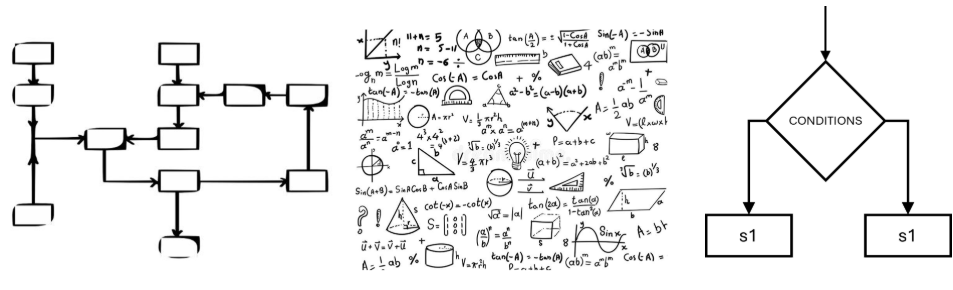

## Objetivos
- Criar e usar **Stored Procedures**, **Functions** e **Triggers** no **MySQL**.
- Conectar ao MySQL usando **PyMySQL** a partir do **Python**.
- Registrar e analisar **auditoria** de alterações (triggers).
- Visualizar resultados com **pandas** e **matplotlib**.

#### Passo 1: Importar bibliotecas

In [ ]:
import pymysql
import pandas as pd
import matplotlib.pyplot as plt

#### Passo 2: Conexão ao MySQL (criando `conn` e `cursor`)

In [ ]:
# 1. Criar conexão com o servidor MySQL (sem selecionar banco ainda)
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root", 
    autocommit=False  # manteremos controle explícito de commit
)
cursor = conn.cursor()
print("Conexão criada com sucesso!")

#### Passo 3: Criar o banco de dados e selecioná-lo
**O que faremos agora:**  
1. Criar o banco `empresa_dados` (se não existir).  
2. Selecionar o banco com `USE`.  
3. Conferir qual banco está em uso.

In [ ]:
cursor.execute('DROP DATABASE IF EXISTS pft') # Remove banco das aulas passadas
cursor.execute('CREATE DATABASE IF NOT EXISTS pft')
print('Banco criado')

In [ ]:
cursor.execute('USE pft')

#### Passo 4: Criar tabelas

#### 4.1) Tabela `departamentos`
Campos principais:  
- `id` (chave primária)  
- `nome` (nome do departamento)

In [ ]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL
);
""")
conn.commit()
print("Tabela 'departamentos' criada com sucesso!")

#### 4.2) Tabela `funcionarios`
Campos principais:  
- `id`, `nome`, `salario`, `dept_id` (chave estrangeira para `departamentos`).

In [ ]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    salario DECIMAL(10,2) NOT NULL,
    dept_id INT,
    FOREIGN KEY (dept_id) REFERENCES departamentos(id)
);
""")
conn.commit()
print("Tabela 'funcionarios' criada com sucesso!")

#### 4.3) Tabela `auditoria_salarios`
Finalidade: armazenar o **histórico** de alterações de salário para cada funcionário.

In [ ]:
#cursor.execute('DROP 
cursor.execute("""
CREATE TABLE IF NOT EXISTS auditoria_salarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    funcionario_id INT,
    salario_antigo DECIMAL(10,2),
    salario_novo DECIMAL(10,2),
    data_alteracao TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
""")
conn.commit()
print("Tabela 'auditoria_salarios' criada com sucesso!")


## 5) Inserir dados de exemplo
**O que faremos agora:**  
- Inserir alguns departamentos e funcionários para podermos testar nossas rotinas.


In [ ]:
departamentos = [("Dados",),("TI",),("Financeiro",),("RH",)]
cursor.executemany('INSERT INTO departamentos (nome) VALUES (%s)',departamentos)
conn.commit()

In [ ]:
funcionarios = [
    ("Sandro", 15000, 1),
    ("Ramon", 7500, 2),
    ("Matheus", 9000, 3),
    ("Rafael", 2500, 1),
    ("Arnon", 25000, 4)
]
cursor.executemany('INSERT INTO funcionarios (nome, salario, dept_id) VALUES (%s,%s,%s)',funcionarios)
conn.commit()


### 5.1) Visualizar os dados atuais dos funcionários
**O que faremos agora:**  
- Executar um `SELECT` e visualizar o resultado em um DataFrame do `pandas`.


In [ ]:
cursor.execute('SELECT * FROM funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])


## 6) Stored Procedures — exemplos práticos
As **procedures** são rotinas armazenadas que executam tarefas no servidor MySQL.



### 6.1) Procedure `listar_funcionarios()`
**Objetivo:** retornar todos os funcionários.  
> **Importante:** no MySQL Workbench usa-se `DELIMITER`, mas aqui estamos executando via driver Python, que aceita o bloco diretamente.


In [ ]:
cursor.execute('DROP PROCEDURE IF EXISTS listar_funcionarios;')
cursor.execute("""
CREATE PROCEDURE listar_funcionarios()
BEGIN
    SELECT * FROM funcionarios ORDER BY id;
END;
""")
conn.commit()              

In [ ]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])


### 6.2) Procedure `funcionarios_por_departamento(IN p_dept INT)`
**Objetivo:** listar funcionários de um departamento específico, com nome do departamento.


In [ ]:
cursor.execute("""
CREATE PROCEDURE funcionarios_por_departamentos(IN p_dept INT)
BEGIN
    SELECT f.id, f.nome, f.salario, d.nome AS departamento
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    WHERE f.dept_id = p_dept
    ORDER BY f.salario DESC;
END;
""")
conn.commit()

In [ ]:
args = (4,)
cursor.callproc('funcionarios_por_departamentos',args)
cursor.fetchall()


### 6.3) Procedure `reajuste_salario(IN p_fator DECIMAL)`
**Objetivo:** multiplicar os salários pelo fator informado (ex.: `1.10` = +10%).


In [ ]:
cursor.execute('DROP PROCEDURE IF EXISTS reajuste_salario;')
cursor.execute("""
CREATE PROCEDURE reajuste_salario(IN p_fator DECIMAL(5,4))
BEGIN
    UPDATE funcionarios SET salario = ROUND(salario * p_fator, 2);
END;
""")
conn.commit()

In [ ]:
base = (1.10,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [ ]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])


## 7) Functions — cálculos reutilizáveis
As **functions** retornam **um valor** e podem ser usadas em `SELECT`, `WHERE`, `ORDER BY` etc.



### 7.1) Função `calcular_bonus(p_salario)`
**Objetivo:** retornar 15% do salário.


In [ ]:
cursor.execute('DROP FUNCTION IF EXISTS calcular_bonus;')
cursor.execute("""
CREATE FUNCTION calcular_bonus(p_salario DECIMAL(10,2)) RETURNS DECIMAL(10,2)
DETERMINISTIC
BEGIN
    DECLARE v_bonus DECIMAL(10,2);
    SET v_bonus = ROUND(p_salario * 0.15, 2);
    RETURN v_bonus;
END;
""")
conn.commit()

In [ ]:
cursor.execute("""SELECT nome, salario, calcular_bonus(salario)
AS bonus FROM funcionarios ORDER BY salario DESC;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Bônus'])


### 7.2) Função `classificar_salario(p_valor)`
**Objetivo:** classificar em **Baixo**, **Médio** ou **Alto**.


In [ ]:
cursor.execute('DROP FUNCTION IF EXISTS classificar_salario;')
cursor.execute("""
CREATE FUNCTION classificar_salario(p_valor DECIMAL(10,2)) RETURNS VARCHAR(20)
DETERMINISTIC
BEGIN
    DECLARE v_cat VARCHAR(20);
    IF p_valor < 3000 THEN
        SET v_cat = 'Baixo';
    ELSEIF p_valor BETWEEN 3000 AND 15000 THEN
        SET v_cat = 'Médio';
    ELSE 
        SET v_cat = 'Alto';
    END IF;
    RETURN v_cat;
END;
""")
conn.commit()

In [ ]:
cursor.execute("""SELECT nome, salario, classificar_salario(salario)
AS faixa FROM funcionarios ORDER BY salario;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Faixa'])


## 8) Triggers — auditoria e validação
As **triggers** reagem automaticamente a eventos (INSERT/UPDATE/DELETE).



### 8.1) Trigger de auditoria (após UPDATE)
**Objetivo:** quando o salário mudar, registrar no log `auditoria_salarios`.


In [ ]:
cursor.execute('DROP TRIGGER IF EXISTS trg_auditar_salario')
cursor.execute("""
CREATE TRIGGER trg_auditar_salario
AFTER UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF OLD.salario <> NEW.salario THEN
        INSERT INTO auditoria_salarios(funcionario_id, salario_antigo, salario_novo)
        VALUES (OLD.id, OLD.salario, NEW.salario);
    END IF;
END;
""")
conn.commit()


### 8.2) Trigger de validação (antes do UPDATE)
**Objetivo:** bloquear aumentos **maiores que 50%**.


In [ ]:
# SIGNAL SQLSTATE '45000' lança erro manualmente
# 45000 é um código genérico usado para indicar que ocorreu um erro definido pelo usuário
cursor.execute('DROP TRIGGER IF EXISTS trg_validar_reajuste;')
cursor.execute("""
CREATE TRIGGER trg_validar_reajuste
BEFORE UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF NEW.salario > OLD.salario * 1.5 THEN
        SIGNAL SQLSTATE '45000' SET MESSAGE_TEXT = 'Aumento acima de 50% - não permitido';
    END IF;
END;
""")
conn.commit()


## 9) Testes dos mecanismos (reajuste + auditoria + validação)
**O que faremos agora:**  
1. Aplicar um reajuste **de 5%** usando a procedure.  
2. Conferir os registros de **auditoria**.  
3. Testar um aumento proibido (**> 50%**) e ver a mensagem de erro.


In [ ]:
base = (1.05,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [ ]:
cursor.execute('SELECT * FROM auditoria_salarios ORDER BY id;')
columns= ['id','funcionario_id', 'salario_antigo', 'salario_novo','Data da modificação']
pd.DataFrame(cursor.fetchall(), columns= columns)

In [ ]:
try:
    cursor.execute('UPDATE funcionarios SET salario = salario * 1.40 WHERE id = 2;')
    conn.commit()
    print('Atualização aplicada com sucesso')
except Exception as e:
    conn.rollback()
    print('Erro esperado  da Trigger:', e)


## 10) Visualizações com `pandas` + `matplotlib`
Vamos criar três gráficos simples para comunicar resultados:
1. **Barras:** alterações por funcionário.  
2. **Linha:** alterações por dia.  
3. **Barras:** média salarial por departamento.


In [ ]:
cursor.execute("""
    SELECT f.nome, COUNT(a.id) AS qtd
    FROM funcionarios f
    LEFT JOIN auditoria_salarios a ON a.funcionario_id = f.id
    GROUP BY f.id, f.nome
    ORDER BY qtd DESC, f.nome
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['nome','qtd'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['nome'], df_qtd['qtd'])
plt.title('Alterações por funcionário')
plt.xlabel('Funcionários')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

In [ ]:
cursor.execute("""
    SELECT DATE(data_alteracao) AS dia, COUNT(*) AS qtd
    FROM auditoria_salarios
    GROUP BY DATE(data_alteracao)
    ORDER BY dia
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['dia','qtd'])

plt.figure(figsize=(4,2))
plt.plot(df_qtd['dia'], df_qtd['qtd'], marker = 'o')
plt.title('Alterações por dia')
plt.xlabel('Dia')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

In [ ]:
cursor.execute("""
    SELECT d.nome AS departamento, ROUND(AVG(f.salario),2) AS media
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    GROUP BY d.id, d.nome
    ORDER BY media DESC
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['departamento','media'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['departamento'], df_qtd['media'])
plt.title('Média Salarial por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Média Salarial')
plt.xticks(rotation = 45)
plt.show()


## 11) Exercícios propostos
1. **Procedure** `add_funcionario(IN p_nome, IN p_salario, IN p_dept)` que insere e emite `SELECT LAST_INSERT_ID()` para retornar o novo `id` ao Python.  
2. **Function** `calc_imposto(p_salario)` (10%) e consulta com salário líquido.  
3. **Trigger** que bloqueia **redução** maior que 30% do salário.  
4. **Relatório**: `nome, departamento, salario, bonus, faixa` ordenado por `bonus` (use as funções).


### Exercício 1 — Procedure add_funcionario

Crie uma procedure chamada add_funcionario que receba como entrada:
- `p_nome` (nome do funcionário)
- `p_salario` (valor do salário)
- `p_dept` (departamento)

E retorne via **OUT** o `ID` do **funcionário recém-inserido**.

In [ ]:
cursor.execute('DROP PROCEDURE IF EXISTS add_funcionario')
cursor.execute("""
CREATE PROCEDURE add_funcionario(
    IN p_nome VARCHAR(100),
    IN p_salario DECIMAL(10,2),
    IN p_dept INT
)
BEGIN
    INSERT INTO funcionarios (nome, salario, dept_id)
    VALUES (p_nome, p_salario, p_dept);
    
    SELECT LAST_INSERT_ID() AS novo_id;
END
""")
conn.commit()

In [ ]:
args = ["Samanta", 15000, 2]
cursor.callproc('add_funcionario',args)
conn.commit()
cursor.fetchone()

### Exercício 2 — Function calc_imposto

Crie uma função chamada `calc_imposto(p_salario)` que retorne o valor do **salário líquido**, descontando **10% de imposto**.

### Exercício 3 — Trigger trg_validar_reducao

Crie uma trigger chamada `trg_validar_reducao` que impede reduções maiores que 30% no salário de um funcionário.

### Exercício 4 — Relatório combinado

Crie uma consulta que mostre:
- `nome`, `departamento`, `salario`,
- `bonus` (usando `calcular_bonus`),
- `faixa` (usando `classificar_salario`),
- `salario_liquido` (usando `calc_imposto`)


## 12) Encerrar a conexão
**O que faremos agora:**  
- Fechar `cursor` e `conn` ao final do notebook.
